TensorFlow: 2.21.0
Extracting dataset...
Dataset ready!
Loading images...
Images loaded: 39209
Classes: 43
Training images: 31367
Validation images: 7842


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 2, 2, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │         5,547 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 164,459 (642.42 KB)

 Trainable params: 164,459 (642.42 KB)

 Non-trainable params: 0 (0.00 B)


Training CNN model...
Epoch 1/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 49s 97ms/step - accuracy: 0.4784 - loss: 1.8517 - val_accuracy: 0.8759 - val_loss: 0.4561
Epoch 2/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 49s 99ms/step - accuracy: 0.8833 - loss: 0.3908 - val_accuracy: 0.9656 - val_loss: 0.1465
Epoch 3/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 47s 95ms/step - accuracy: 0.9426 - loss: 0.1959 - val_accuracy: 0.9767 - val_loss: 0.0989
Epoch 4/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 47s 95ms/step - accuracy: 0.9657 - loss: 0.1159 - val_accuracy: 0.9819 - val_loss: 0.0594
Epoch 5/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 85s 101ms/step - accuracy: 0.9753 - loss: 0.0866 - val_accuracy: 0.9832 - val_loss: 0.0565
Epoch 6/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 81s 100ms/step - accuracy: 0.9812 - loss: 0.0668 - val_accuracy: 0.9904 - val_loss: 0.0367
Epoch 7/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 48s 99ms/step - accuracy: 0.9852 - loss: 0.0494 - val_accuracy: 0.9876 - val_loss: 0.0407
Epoch 8/10
491/491 ━━━━━━━━━━━━━━━━━━━━ 83s 102ms/step - accuracy

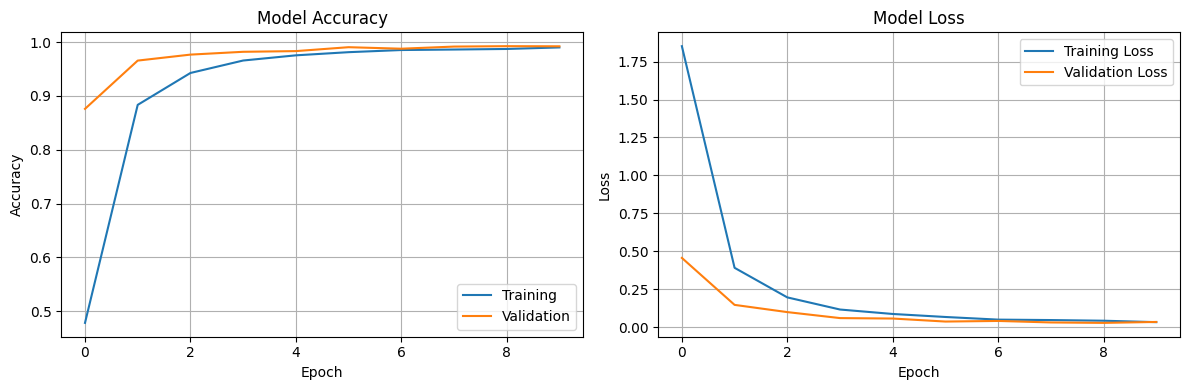


Upload a traffic sign image:


Saving 9b32f40584c3dd4ce0cb94dcc18bd6e8.jpg to 9b32f40584c3dd4ce0cb94dcc18bd6e8.jpg

========== RECOGNITION RESULT ==========
Traffic Sign: Yield
Class ID: 13
Confidence: 84.04 %


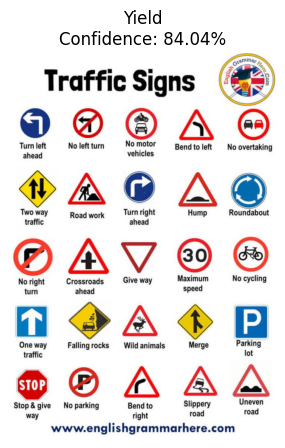


Webcam recognition starting...


<IPython.core.display.Javascript object>

Webcam unavailable: NotAllowedError: Permission denied

Model saved successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


TRAFFIC SIGN RECOGNITION PROJECT COMPLETED!


In [3]:
# ============================================================
# REAL-TIME TRAFFIC SIGN RECOGNITION
# CNN + TensorFlow + OpenCV + GTSRB
# Google Colab - SINGLE CELL EXECUTION
# ============================================================

!pip install -q tensorflow opencv-python scikit-learn

import os, glob, zipfile, urllib.request
import numpy as np
import cv2
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from google.colab import files
from google.colab.output import eval_js
from IPython.display import display, Javascript
from base64 import b64decode
from PIL import Image
import io

print("TensorFlow:", tf.__version__)

# ============================================================
# 1. DOWNLOAD DATASET (FIXED - NO TFDS)
# ============================================================

url = "https://sid.erda.dk/public/archives/daaeac0d7ce1152aea9b61d9f1e19370/GTSRB_Final_Training_Images.zip"

zip_path = "/content/GTSRB_Training.zip"
extract_path = "/content/GTSRB_Dataset"

if not os.path.exists(extract_path):
    print("Downloading traffic sign dataset...")
    urllib.request.urlretrieve(url, zip_path)

    print("Extracting dataset...")
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

print("Dataset ready!")

# ============================================================
# 2. LOAD IMAGES
# ============================================================

IMG_SIZE = 32

image_paths = glob.glob(
    os.path.join(extract_path, "**", "*.ppm"),
    recursive=True
)

X = []
y = []

print("Loading images...")

for path in image_paths:
    try:
        # Class ID comes from the class folder name
        class_id = int(os.path.basename(os.path.dirname(path)))

        img = cv2.imread(path)
        if img is None:
            continue

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

        X.append(img)
        y.append(class_id)

    except (ValueError, Exception):
        continue

X = np.array(X, dtype=np.float32) / 255.0
y = np.array(y, dtype=np.int64)

print("Images loaded:", len(X))
print("Classes:", len(np.unique(y)))

# ============================================================
# 3. TRAIN / VALIDATION SPLIT
# ============================================================

X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))

# ============================================================
# 4. CNN MODEL
# ============================================================

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),

    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.Conv2D(128, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(2),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(43, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# ============================================================
# 5. TRAIN CNN
# ============================================================

print("\nTraining CNN model...")

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=64
)

# ============================================================
# 6. EVALUATION
# ============================================================

loss, accuracy = model.evaluate(X_val, y_val, verbose=0)

print("\nModel Accuracy:", round(accuracy * 100, 2), "%")
print("Model Loss:", round(loss, 4))

# ============================================================
# 7. ACCURACY AND LOSS GRAPH
# ============================================================

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

# ============================================================
# 8. TRAFFIC SIGN CLASS NAMES
# ============================================================

class_names = [
    "Speed limit 20", "Speed limit 30", "Speed limit 50",
    "Speed limit 60", "Speed limit 70", "Speed limit 80",
    "End speed limit 80", "Speed limit 100", "Speed limit 120",
    "No passing", "No passing heavy vehicles",
    "Right of way at intersection", "Priority road", "Yield",
    "Stop", "No vehicles", "No entry", "Danger",
    "Bend left", "Bend right", "Double bend",
    "Uneven road", "Slippery road", "Road narrows",
    "Road work", "Traffic signals", "Pedestrians",
    "Children crossing", "Bicycles crossing", "Snow",
    "Wild animals", "End of restrictions",
    "Turn right", "Turn left", "Ahead only",
    "Straight or right", "Straight or left",
    "Keep right", "Keep left", "Roundabout",
    "End of no passing", "End of restrictions heavy vehicles"
]

# ============================================================
# 9. PREDICTION FUNCTION
# ============================================================

def predict_sign(img):

    resized = cv2.resize(img, (32, 32))
    resized = resized.astype(np.float32) / 255.0
    resized = np.expand_dims(resized, axis=0)

    prediction = model.predict(resized, verbose=0)[0]

    class_id = int(np.argmax(prediction))
    confidence = float(prediction[class_id]) * 100

    sign_name = class_names[class_id]

    print("\n========== RECOGNITION RESULT ==========")
    print("Traffic Sign:", sign_name)
    print("Class ID:", class_id)
    print("Confidence:", round(confidence, 2), "%")
    print("=====================================")

    plt.figure(figsize=(6, 5))
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"{sign_name}\nConfidence: {confidence:.2f}%")
    plt.show()

    return class_id, sign_name, confidence

# ============================================================
# 10. UPLOAD TRAFFIC SIGN IMAGE
# ============================================================

print("\nUpload a traffic sign image:")

uploaded = files.upload()

for filename in uploaded.keys():

    img = cv2.imread(filename)

    if img is not None:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        predict_sign(img)
    else:
        print("Could not read uploaded image.")

# ============================================================
# 11. WEBCAM CAPTURE (GOOGLE COLAB)
# ============================================================

def capture_webcam():

    display(Javascript("""
    async function captureImage() {

        const div = document.createElement('div');

        const button = document.createElement('button');
        button.textContent = 'Capture Traffic Sign';
        div.appendChild(button);

        const video = document.createElement('video');
        video.style.display = 'block';
        video.style.width = '480px';
        div.appendChild(video);

        document.body.appendChild(div);

        const stream = await navigator.mediaDevices.getUserMedia({
            video: true
        });

        video.srcObject = stream;
        await video.play();

        await new Promise(resolve => button.onclick = resolve);

        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;

        canvas.getContext('2d').drawImage(video, 0, 0);

        stream.getTracks().forEach(track => track.stop());
        div.remove();

        return canvas.toDataURL('image/jpeg');
    }
    """))

    data = eval_js("captureImage()")
    return b64decode(data.split(",")[1])

print("\nWebcam recognition starting...")

try:
    photo = capture_webcam()

    pil_img = Image.open(io.BytesIO(photo)).convert("RGB")
    webcam_img = np.array(pil_img)

    predict_sign(webcam_img)

except Exception as e:
    print("Webcam unavailable:", e)

# ============================================================
# 12. SAVE AND DOWNLOAD MODEL
# ============================================================

model.save("/content/traffic_sign_model.keras")

print("\nModel saved successfully!")

files.download("/content/traffic_sign_model.keras")

print("\nTRAFFIC SIGN RECOGNITION PROJECT COMPLETED!")